# Try 2

In [1]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import tifffile as tiff


In [2]:
# ================= PATHS =================
BASE_DIR = Path("DMID_Dataset")
TIFF_DIR = BASE_DIR / "TIFF Images"
MASK_DIR = BASE_DIR / "ROI Masks"
META_PATH = BASE_DIR / "Metadata.xlsx"

PATCH_SIZE  = 128
NUM_PATCHES = 9
ROI_SCALE   = 1.5


In [3]:
def normalize_id(s):
    """IMG_001 / IMG001 / IMG001  -> IMG001"""
    return str(s).strip().upper().replace("_", "")


In [4]:
def load_tiff(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise RuntimeError(f"Cannot load TIFF: {path}")
    return img


In [5]:
def load_mask(path):
    try:
        m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
        if m is None:
            raise Exception
    except:
        try:
            m = np.array(Image.open(path))
        except:
            m = tiff.imread(path)

    if len(m.shape) == 3:
        m = m[:, :, 0]

    return (m > 0).astype(np.uint8)


In [6]:
def mask_to_bbox(mask, margin=10):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return None

    x1, x2 = xs.min(), xs.max()
    y1, y2 = ys.min(), ys.max()

    return (
        max(0, x1 - margin),
        max(0, y1 - margin),
        min(mask.shape[1], x2 + margin),
        min(mask.shape[0], y2 + margin)
    )


In [7]:
def roi_from_metadata(img, x, y, r, scale=1.5):
    h, w = img.shape
    r = int(float(r) * scale)
    x, y = int(float(x)), int(float(y))

    x1 = max(0, x - r)
    y1 = max(0, y - r)
    x2 = min(w, x + r)
    y2 = min(h, y + r)

    return img[y1:y2, x1:x2]


In [8]:
def extract_patches(roi, patch_size=128, num_patches=9):
    h, w = roi.shape
    patches = []

    for _ in range(num_patches):
        if h < patch_size or w < patch_size:
            patch = cv2.resize(roi, (patch_size, patch_size))
        else:
            x = np.random.randint(0, w - patch_size)
            y = np.random.randint(0, h - patch_size)
            patch = roi[y:y+patch_size, x:x+patch_size]
        patches.append(patch)

    return np.stack(patches)


In [9]:
tiff_map = {normalize_id(p.stem): p for p in TIFF_DIR.glob("*.tif*")}
mask_map = {normalize_id(p.stem): p for p in MASK_DIR.glob("*.tif*")}

print("TIFF files:", len(tiff_map))
print("MASK files:", len(mask_map))


TIFF files: 511
MASK files: 269


In [10]:
df = pd.read_excel(META_PATH, skiprows=31, header=None)

# Clean image IDs (THIS FIXES YOUR MISMATCH)
df[0] = df[0].astype(str).str.strip().str.upper()

IMG_COL   = 0
CLASS_COL = 4
X_COL     = 5
Y_COL     = 6
R_COL     = 7

abnormal_df = df[df[CLASS_COL].isin(["B", "M"])]

# Unique abnormal image IDs
abnormal_ids = abnormal_df[IMG_COL].unique()

print("Abnormal images (metadata):", len(abnormal_ids))


Abnormal images (metadata): 257


In [ ]:
bags   = []
labels = []

used_mask = 0
used_meta = 0
used_center = 0

for img_id in abnormal_ids:
    key = normalize_id(img_id)

    if key not in tiff_map:
        continue

    img = load_tiff(tiff_map[key])

    # all metadata rows for this image
    rows = abnormal_df[abnormal_df[IMG_COL] == img_id]

    # image-level label
    image_label = 1 if (rows[CLASS_COL] == "M").any() else 0

    roi = None

    # =========================
    # 1️⃣ Try ROI MASK
    # =========================
    if key in mask_map:
        mask = load_mask(mask_map[key])
        bbox = mask_to_bbox(mask)

        if bbox is not None:
            x1, y1, x2, y2 = bbox
            roi = img[y1:y2, x1:x2]
            used_mask += 1

    # Try METADATA ROI
    if roi is None:
        valid_rows = rows[
            rows[X_COL].notna() &
            rows[Y_COL].notna() &
            rows[R_COL].notna()
        ]

        if len(valid_rows) > 0:
            row = valid_rows.loc[
                valid_rows[R_COL].astype(float).idxmax()
            ]

            roi = roi_from_metadata(
                img,
                row[X_COL],
                row[Y_COL],
                row[R_COL],
                scale=ROI_SCALE
            )
            used_meta += 1

    # FINAL fallback: center crop
    if roi is None:
        h, w = img.shape
        c_y, c_x = h // 2, w // 2
        half = PATCH_SIZE * 2

        roi = img[
            max(0, c_y - half): min(h, c_y + half),
            max(0, c_x - half): min(w, c_x + half)
        ]
        used_center += 1

    # PATCH EXTRACTION (MIL instances)
    patches = extract_patches(roi, PATCH_SIZE, NUM_PATCHES)
    patches = patches.astype(np.float32) / 255.0
    patches = patches[:, None, :, :]  # (N,1,H,W)

    bags.append(patches)
    labels.append(image_label)


TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDirectory: Incorrect count for "SampleFormat".
TIFFReadDi

In [12]:
print("\n========== FINAL SUMMARY ==========")
print("Total MIL bags created :", len(bags))
print("Used ROI mask          :", used_mask)
print("Used metadata ROI      :", used_meta)
print("Bag shape              :", bags[0].shape)
print("Label distribution     :", np.unique(labels, return_counts=True))



========== FINAL SUMMARY ==========
Total MIL bags created : 257
Used ROI mask          : 251
Used metadata ROI      : 5
Bag shape              : (9, 1, 128, 128)
Label distribution     : (array([0, 1]), array([136, 121]))


In [14]:
import torch

save_path = "0_dmid_mil_bags.pt"

torch.save(
    {
        "bags": bags,      # list of (9,1,128,128)
        "labels": labels   # list of 0/1
    },
    save_path
)

print("Saved to:", save_path)


Saved to: 0_dmid_mil_bags.pt


In [16]:
import torch
import numpy as np

data = torch.load("0_dmid_mil_bags.pt", weights_only=False)

bags   = data["bags"]
labels = data["labels"]

print("Total bags:", len(bags))


Total bags: 257


In [17]:
total_patches = sum(bag.shape[0] for bag in bags)
print("Total patches across all bags:", total_patches)


Total patches across all bags: 2313


In [18]:
patch_counts = [bag.shape[0] for bag in bags]

print("Unique patch counts:", set(patch_counts))
print("Min patches per bag:", min(patch_counts))
print("Max patches per bag:", max(patch_counts))


Unique patch counts: {9}
Min patches per bag: 9
Max patches per bag: 9


In [19]:
print("Example bag shape:", bags[0].shape)
print("Example bag dtype:", bags[0].dtype)


Example bag shape: (9, 1, 128, 128)
Example bag dtype: float32


In [20]:
import numpy as np

labels_np = np.array(labels)

print("Benign (0):", np.sum(labels_np == 0))
print("Malignant (1):", np.sum(labels_np == 1))


Benign (0): 136
Malignant (1): 121


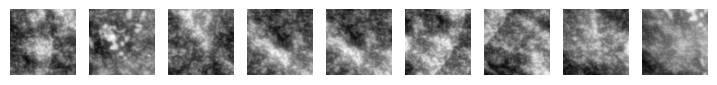

In [21]:
import matplotlib.pyplot as plt

bag = bags[0]

plt.figure(figsize=(9,3))
for i in range(bag.shape[0]):
    plt.subplot(1, bag.shape[0], i+1)
    plt.imshow(bag[i,0], cmap="gray")
    plt.axis("off")
plt.show()
